In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
from src.data_preparation import OCTMNISTDataPreprocessor
preprocessor=OCTMNISTDataPreprocessor(data_path="../data/octmnist_64.npz")
X_train,X_val, X_test, y_train, y_val, y_test = preprocessor.load_dataset()

Loading OCTMNIST data...
Original splits loaded: Training Datapoints: 97477, Validation Datapoints: 10832, Test Datapoints: 1000
Total Data Points: 109309
Creating new stratified splits...
New splits created: Training Datapoints: 76516, Validation Datapoints: 16396, Test Datapoints: 16397
Shapes of returned Splits: X_train: (76516, 64, 64, 1), X_val: (16396, 64, 64, 1), X_test: (16397, 64, 64, 1)
Shapes of returned Labels: y_train: (76516,), y_val: (16396,), y_test: (16397,)


In [2]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class OCT(Dataset):
    def __init__(self, X, y):
        X = np.asarray(X).squeeze()              # (N, 64, 64)
        if X.max() > 1.0:                        # make sure values are in [0, 1]
            X = X / 255.0
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(np.asarray(y).ravel(), dtype=torch.long)
        self.norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = self.X[i].unsqueeze(0).repeat(3, 1, 1)   # grayscale -> 3 channels
        return self.norm(img), self.y[i]

train_dl = DataLoader(OCT(X_train, y_train), batch_size=128, shuffle=True)
val_dl   = DataLoader(OCT(X_val,   y_val),   batch_size=128)
test_dl  = DataLoader(OCT(X_test,  y_test),  batch_size=128)

In [4]:
import time, json
import torch.nn as nn
from torchvision import models
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, precision_score, recall_score)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
print("Device:", device)

NUM_CLASSES = len(np.unique(y_train))
CLASS_NAMES = ["CNV", "DME", "drusen", "normal"]
os.makedirs("../results", exist_ok=True)
crit = nn.CrossEntropyLoss()

Device: cpu


In [5]:
# ---------- build a pretrained model with a new final layer ----------
def build_model(name):
    if name == "squeezenet":
        m = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Conv2d(512, NUM_CLASSES, kernel_size=1)  # 1000 -> 4
        m.num_classes = NUM_CLASSES
    elif name == "mobilenetv2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.last_channel, NUM_CLASSES)      # 1000 -> 4
    return m.to(device)

In [6]:
# ---------- one epoch of training or validation ----------
def run_epoch(model, dl, opt=None):
    train = opt is not None
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = crit(model(xb), yb)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb); n += len(xb)
    return total / n


In [7]:
# ---------- one training phase (frozen head-only OR full fine-tuning) ----------
def train_phase(model, epochs, lr, freeze_backbone, hist, best):
    for p in model.parameters():
        p.requires_grad = not freeze_backbone
    for p in model.classifier.parameters():       # the new head is always trainable
        p.requires_grad = True
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    for ep in range(epochs):
        t0 = time.time()
        tl = run_epoch(model, train_dl, opt)
        vl = run_epoch(model, val_dl)
        hist["train"].append(tl); hist["val"].append(vl); hist["time"].append(time.time() - t0)
        if vl < best["loss"]:                      # keep best weights by validation loss
            best["loss"] = vl
            best["state"] = {k: v.clone() for k, v in model.state_dict().items()}
        print(f"epoch {len(hist['train']):2d} | train {tl:.4f} | val {vl:.4f} | {hist['time'][-1]:.1f}s")


In [8]:
# ---------- full experiment: train, plot, evaluate, measure size ----------
def run_experiment(name, head_epochs=5, ft_epochs=15, head_lr=1e-3, ft_lr=1e-4):
    model = build_model(name)
    hist = {"train": [], "val": [], "time": []}
    best = {"loss": float("inf"), "state": None}

    print("--- Phase 1: train new head only ---")
    train_phase(model, head_epochs, head_lr, True, hist, best)
    print("--- Phase 2: fine-tune whole network ---")
    train_phase(model, ft_epochs, ft_lr, False, hist, best)
    model.load_state_dict(best["state"])

    # loss curves
    plt.figure(figsize=(7, 4))
    plt.plot(hist["train"], label="Train loss"); plt.plot(hist["val"], label="Validation loss")
    plt.axvline(head_epochs - 0.5, ls="--", c="gray", label="Start of fine-tuning")
    plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title(f"{name} loss curves")
    plt.legend(); plt.tight_layout(); plt.savefig(f"../results/{name}_loss.png", dpi=200); plt.show()

    # test evaluation
    model.eval(); preds, labels = [], []
    with torch.no_grad():
        for xb, yb in test_dl:
            preds += model(xb.to(device)).argmax(1).cpu().tolist()
            labels += yb.tolist()
    acc  = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, average="macro", zero_division=0)
    rec  = recall_score(labels, preds, average="macro", zero_division=0)
    cm   = confusion_matrix(labels, preds)
    print(f"\nTest accuracy: {acc:.4f} | macro precision: {prec:.4f} | macro recall: {rec:.4f}")
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4, zero_division=0))

    # confusion matrix heatmap
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45); plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"{name} confusion matrix")
    plt.tight_layout(); plt.savefig(f"../results/{name}_cm.png", dpi=200); plt.show()

    # parameter count and model size
    params = sum(p.numel() for p in model.parameters())
    path = f"../results/{name}.pth"
    torch.save(model.state_dict(), path)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    avg_time = float(np.mean(hist["time"]))
    print(f"Params: {params:,} | Size: {size_mb:.2f} MB | Avg time/epoch: {avg_time:.1f}s")

    res = dict(model=name, params=params, size_mb=round(size_mb, 2),
               time_per_epoch_s=round(avg_time, 1), test_acc=round(acc, 4),
               macro_precision=round(prec, 4), macro_recall=round(rec, 4))
    with open(f"../results/{name}_results.json", "w") as f:
        json.dump(res, f, indent=2)
    return res

Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to C:\Users\Dell/.cache\torch\hub\checkpoints\squeezenet1_1-b8a52dc0.pth


100.0%


--- Phase 1: train new head only ---
epoch  1 | train 0.7749 | val 0.6034 | 143.3s
epoch  2 | train 0.6631 | val 0.5835 | 152.0s
epoch  3 | train 0.6528 | val 0.5874 | 152.4s
epoch  4 | train 0.6494 | val 0.5830 | 154.6s
epoch  5 | train 0.6453 | val 0.5827 | 158.8s
--- Phase 2: fine-tune whole network ---
epoch  6 | train 0.4060 | val 0.3169 | 262.8s
epoch  7 | train 0.2826 | val 0.2805 | 287.5s
epoch  8 | train 0.2380 | val 0.2290 | 345.2s
epoch  9 | train 0.2114 | val 0.2116 | 294.0s
epoch 10 | train 0.1925 | val 0.1994 | 255.5s
epoch 11 | train 0.1779 | val 0.1906 | 283.0s
epoch 12 | train 0.1671 | val 0.1905 | 311.6s
epoch 13 | train 0.1566 | val 0.1904 | 260.9s
epoch 14 | train 0.1449 | val 0.1857 | 279.2s
epoch 15 | train 0.1370 | val 0.1878 | 273.0s
epoch 16 | train 0.1307 | val 0.1822 | 279.5s
epoch 17 | train 0.1219 | val 0.1829 | 250.9s
epoch 18 | train 0.1147 | val 0.1709 | 296.8s
epoch 19 | train 0.1076 | val 0.1999 | 272.6s
epoch 20 | train 0.1009 | val 0.1739 | 257.6s


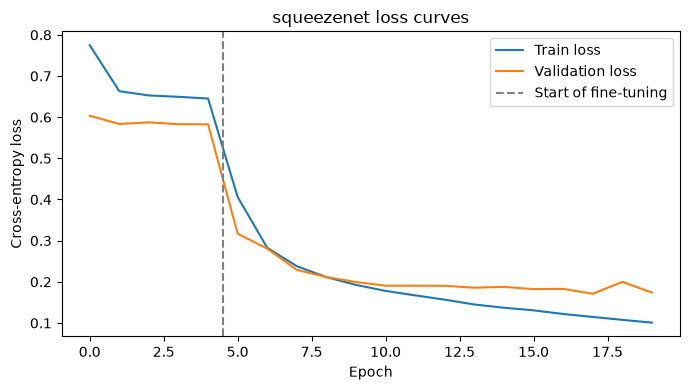


Test accuracy: 0.9450 | macro precision: 0.9126 | macro recall: 0.8904
              precision    recall  f1-score   support

         CNV     0.9580    0.9664    0.9622      5619
         DME     0.9425    0.9051    0.9234      1739
      drusen     0.7903    0.7113    0.7487      1330
      normal     0.9597    0.9787    0.9691      7709

    accuracy                         0.9450     16397
   macro avg     0.9126    0.8904    0.9009     16397
weighted avg     0.9435    0.9450    0.9440     16397



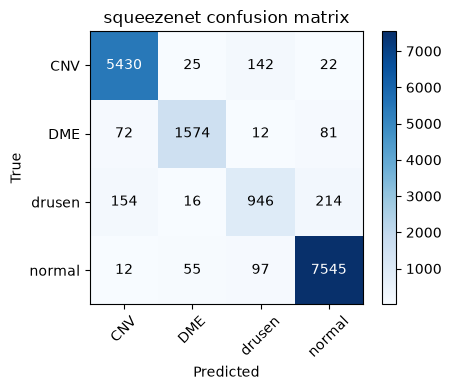

Params: 724,548 | Size: 2.78 MB | Avg time/epoch: 248.6s


{'model': 'squeezenet',
 'params': 724548,
 'size_mb': 2.78,
 'time_per_epoch_s': 248.6,
 'test_acc': 0.945,
 'macro_precision': 0.9126,
 'macro_recall': 0.8904}

In [9]:
res_squeeze = run_experiment("squeezenet")
res_squeeze